# Machine Learning - Assignment 2
## Comparing Classification Models on the Breast Cancer Wisconsin (Diagnostic) Dataset

**Student Name:** M.Tech AIML Scholar
**Student ID:** 2026aj05357
**Date:** 05-Nov-2026

---
Five classifiers (Logistic Regression, Decision Tree, KNN, Naive Bayes, SVM) are trained
on the same dataset, **tuned with 5-fold stratified cross-validated grid search**, and
compared on six evaluation metrics: Accuracy, AUC, Precision, Recall, F1, and MCC.
Class balance is analysed explicitly and handled through cost-sensitive class
weighting, which is itself treated as a tuned hyperparameter. The tuned pipelines
are saved for the companion Streamlit app.

> **NOTE - Class balance handling: the dataset was NOT resampled.**
> - **Data:** no SMOTE, no over- or under-sampling. Train and test both keep the real ~63% Benign / ~37% Malignant ratio.
> - **Training:** `class_weight='balanced'` (or 50/50 priors for Naive Bayes) is part of each model's grid; 5-fold CV decides per model whether it helps. KNN has no weighting option.
> - **Selection metric:** F1 of the positive class (Benign = 1), with AUC and MCC reported alongside.

In [1]:
# Install the exact versions the saved models are built with (same as requirements.txt),
# so the .joblib files load cleanly in the Streamlit app.
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import time
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, confusion_matrix, roc_curve, make_scorer
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_style('whitegrid')
print(f"Libraries imported (scikit-learn {sklearn.__version__})")

Libraries imported (scikit-learn 1.6.1)


## Section 1: Dataset

**Breast Cancer Wisconsin (Diagnostic) dataset** - predicts whether a breast mass biopsy is
**Malignant** (`target = 0`) or **Benign** (`target = 1`) from measurements of cell nuclei in
digitized Fine Needle Aspirate (FNA) images. Source:
[UCI ML Repository](https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic).

- 569 instances, 30 numeric features, binary target
- Ten nuclear properties (radius, texture, perimeter, area, smoothness, compactness, concavity,
  concave points, symmetry, fractal dimension), each as a **mean**, a **standard error** and a **worst** (largest) value
- No categorical features and no missing values

In [3]:
df = pd.read_csv('data/breast_cancer_wisconsin_full.csv')

dataset_name = "Breast Cancer Wisconsin (Diagnostic)"
dataset_source = "https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic"
n_samples_raw, n_features_raw = df.shape[0], df.shape[1] - 1

print(f"Shape: {df.shape}")
display(df.head())

Shape: (569, 31)


,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points,mean_symmetry,mean_fractal_dimension,...,worst_texture,worst_perimeter,worst_area,worst_smoothness,worst_compactness,worst_concavity,worst_concave_points,worst_symmetry,worst_fractal_dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [4]:
display(df.info())
print()
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean_radius              569 non-null    float64
 1   mean_texture             569 non-null    float64
 2   mean_perimeter           569 non-null    float64
 3   mean_area                569 non-null    float64
 4   mean_smoothness          569 non-null    float64
 5   mean_compactness         569 non-null    float64
 6   mean_concavity           569 non-null    float64
 7   mean_concave_points      569 non-null    float64
 8   mean_symmetry            569 non-null    float64
 9   mean_fractal_dimension   569 non-null    float64
 10  radius_error             569 non-null    float64
 11  texture_error            569 non-null    float64
 12  perimeter_error          569 non-null    float64
 13  area_error               569 non-null    float64
 14  smoothness_error         5

None


Missing values: 0
Duplicate rows: 0


## Section 2: Exploratory Data Analysis

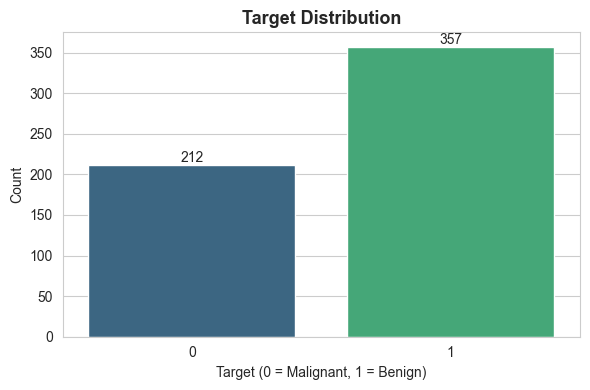

target
1    0.627
0    0.373
Name: proportion, dtype: float64


In [5]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x='target', hue='target', palette='viridis', legend=False)
ax.set_title('Target Distribution', fontsize=13, fontweight='bold')
ax.set_xlabel('Target (0 = Malignant, 1 = Benign)')
ax.set_ylabel('Count')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontsize=10)
plt.tight_layout()
plt.show()

print(df['target'].value_counts(normalize=True).round(3))

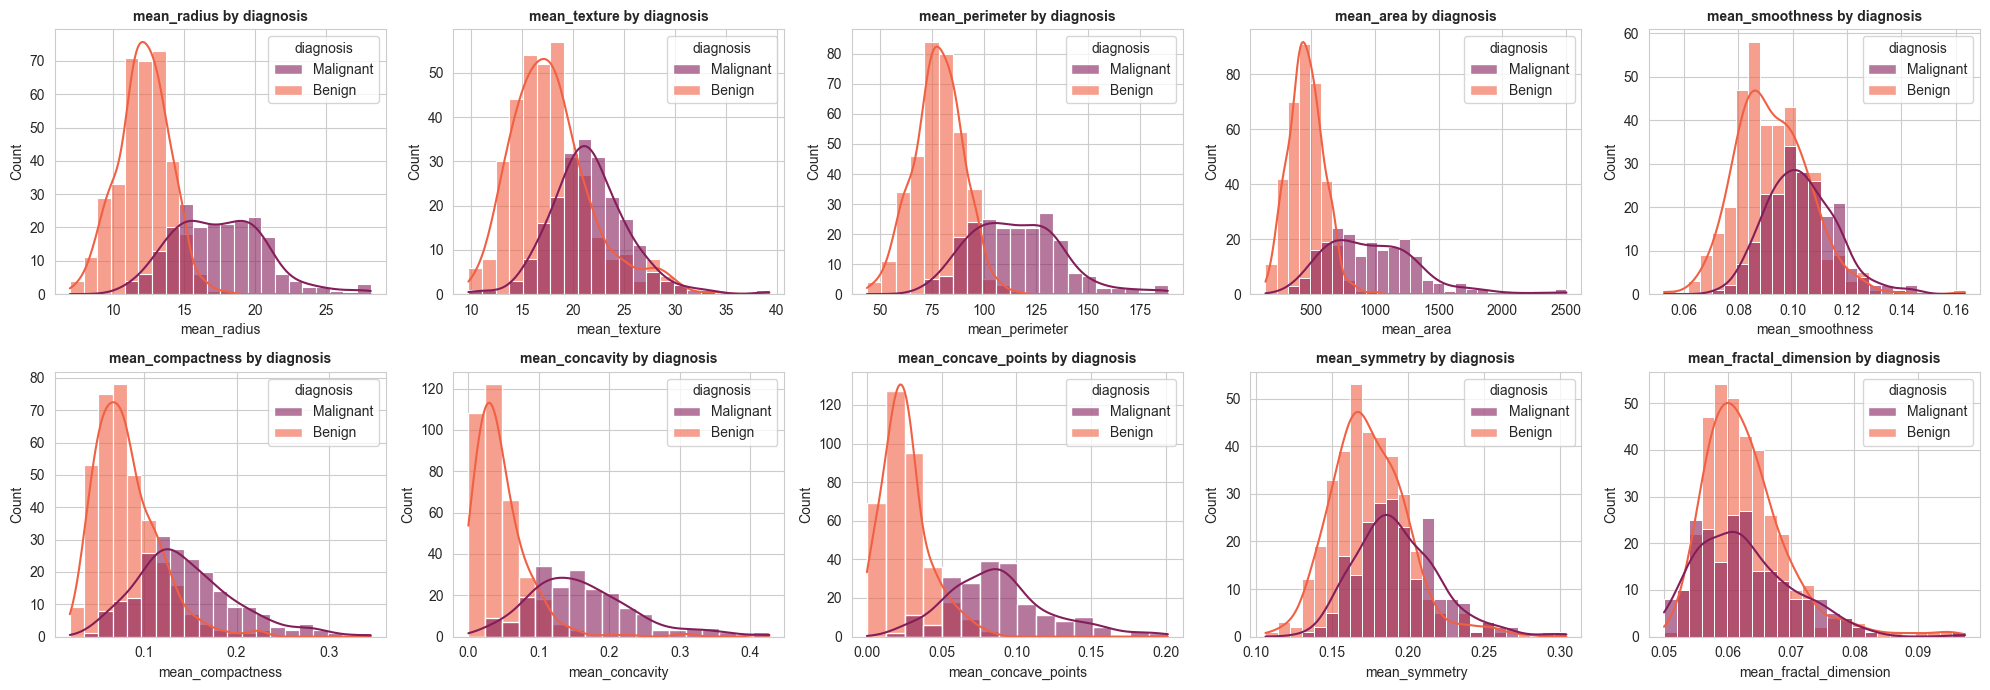

In [6]:
feature_cols = [c for c in df.columns if c != 'target']
mean_cols = [c for c in feature_cols if c.startswith('mean_')]
df_plot = df.assign(diagnosis=df['target'].map({0: 'Malignant', 1: 'Benign'}))

fig, axes = plt.subplots(2, 5, figsize=(20, 7))
axes = axes.flatten()
palette = sns.color_palette('rocket', 2)

for i, col in enumerate(mean_cols):
    sns.histplot(data=df_plot, x=col, hue='diagnosis', palette=palette, kde=True, ax=axes[i], alpha=0.6)
    axes[i].set_title(f'{col} by diagnosis', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

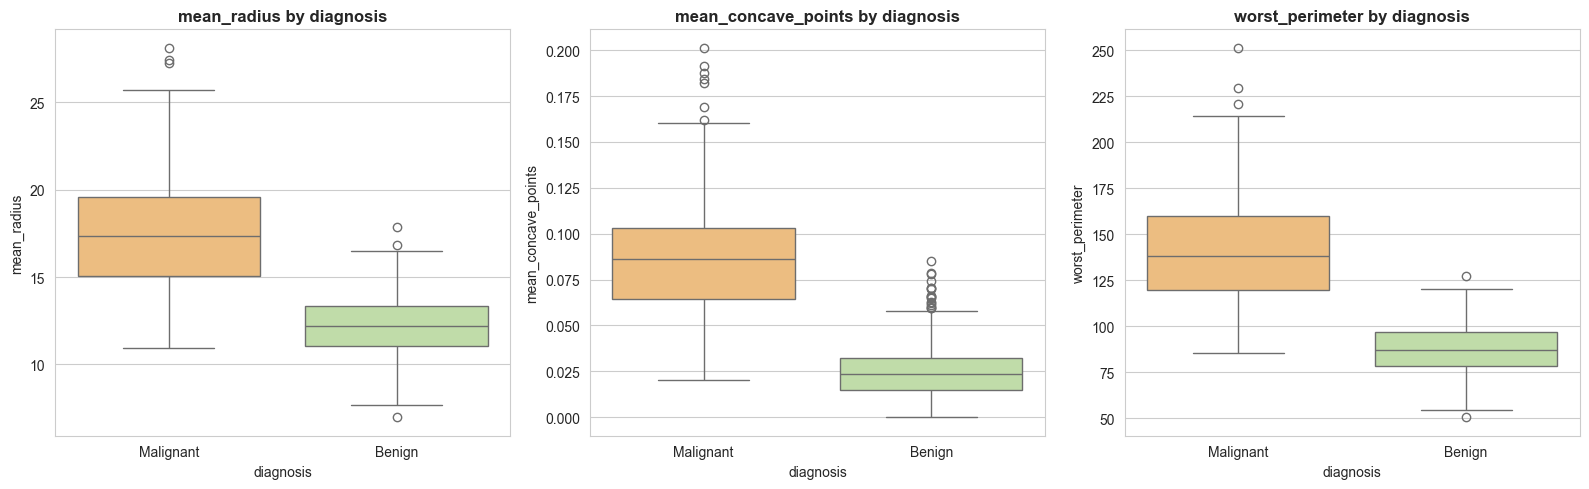

In [7]:
top_cols = ['mean_radius', 'mean_concave_points', 'worst_perimeter']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axes, top_cols):
    sns.boxplot(data=df_plot, x='diagnosis', y=col, hue='diagnosis', palette='Spectral', ax=ax, legend=False)
    ax.set_title(f'{col} by diagnosis', fontweight='bold')

plt.tight_layout()
plt.show()

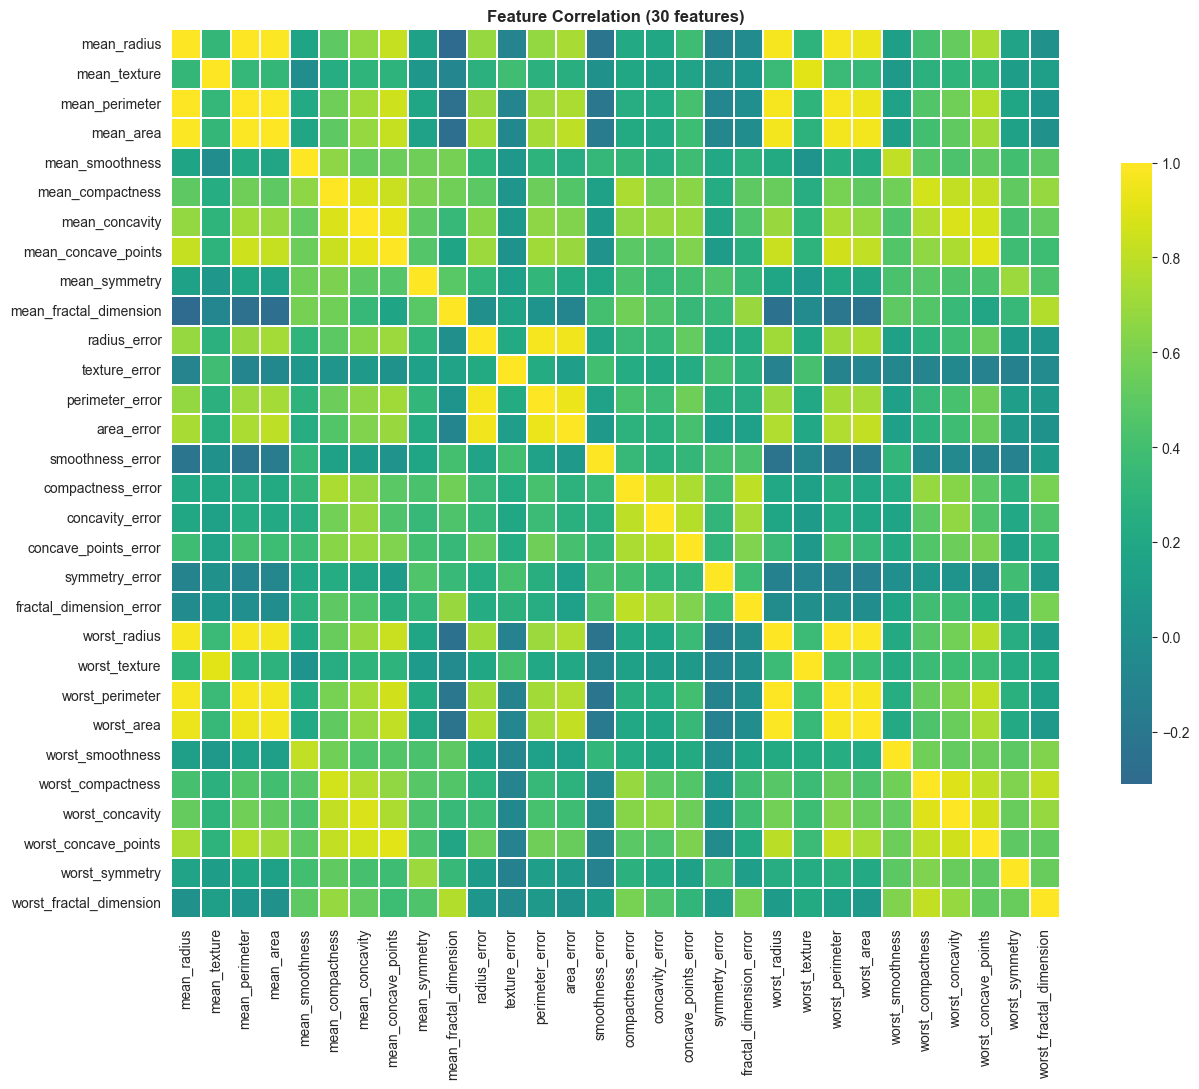

Feature pairs with |correlation| > 0.9: 21


,,|corr|
mean_radius,mean_perimeter,0.997855
worst_radius,worst_perimeter,0.993708
mean_radius,mean_area,0.987357
mean_perimeter,mean_area,0.986507
worst_radius,worst_area,0.984015


In [8]:
plt.figure(figsize=(14, 11))
corr = df[feature_cols].corr()
sns.heatmap(corr, cmap='viridis', center=0, square=True, linewidths=0.2, cbar_kws={'shrink': 0.7})
plt.title('Feature Correlation (30 features)', fontweight='bold')
plt.tight_layout()
plt.show()

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
print(f"Feature pairs with |correlation| > 0.9: {(upper.abs() > 0.9).sum()}")
display(upper.abs().sort_values(ascending=False).head(5).to_frame('|corr|'))

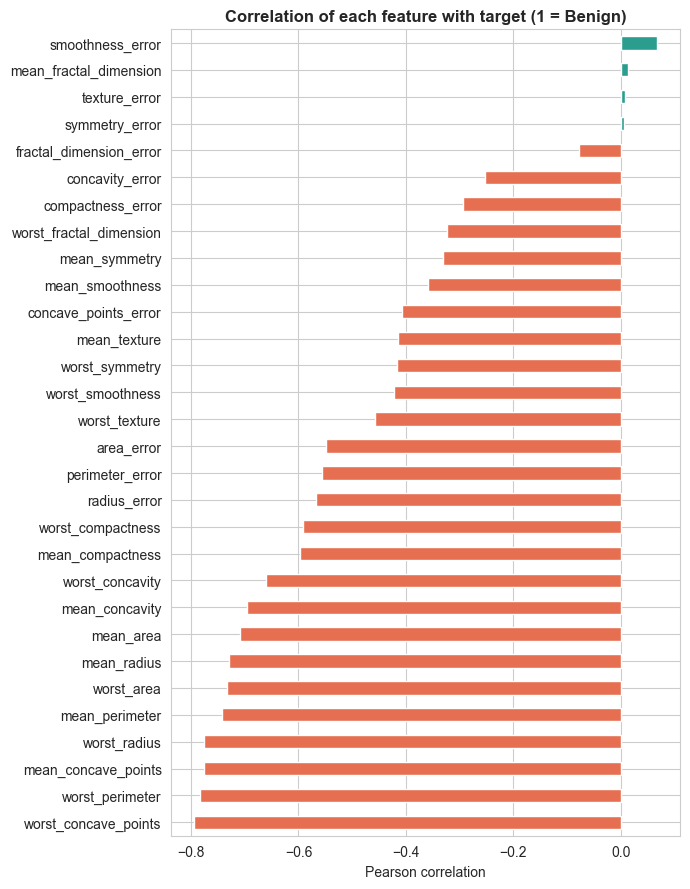

,corr with target
worst_concave_points,-0.793566
worst_perimeter,-0.782914
mean_concave_points,-0.776614
worst_radius,-0.776454
mean_perimeter,-0.742636


In [9]:
target_corr = df.corr()['target'].drop('target').sort_values()

plt.figure(figsize=(7, 9))
target_corr.plot(kind='barh', color=np.where(target_corr < 0, '#e76f51', '#2a9d8f'))
plt.title('Correlation of each feature with target (1 = Benign)', fontweight='bold')
plt.xlabel('Pearson correlation')
plt.tight_layout()
plt.show()

display(target_corr.head(5).to_frame('corr with target'))

**EDA takeaways:**
- Classes are moderately imbalanced (~63% Benign, ~37% Malignant) - motivates using AUC/F1/MCC alongside accuracy.
- Malignant masses have clearly larger nuclei: radius, perimeter, area and concave-point values are shifted well above the Benign distribution, with little overlap in the boxplots.
- The strongest single signals are the `worst_*` and `mean_*` size and concavity features (`worst_concave_points`, `worst_perimeter`, `mean_concave_points`, `worst_radius`), all negatively correlated with `target` (larger value -> more likely Malignant).
- Many features are almost duplicates: radius, perimeter and area are tightly coupled (`mean_radius` vs `mean_perimeter` r = 0.998), and 21 feature pairs exceed |r| = 0.9. This multicollinearity hurts Naive Bayes (independence assumption) and makes KNN distances count the same information several times, but it is harmless for regularised Logistic Regression and SVM.
- A few features (`texture_error`, `mean_fractal_dimension`, `smoothness_error`) barely correlate with the target on their own.

## Section 3: Data Cleaning and Preprocessing

In [10]:
# The data is already clean: 30 numeric features, no missing values, no duplicates,
# and a ready-made binary target. No rows or columns are dropped.
# Scaling is the only preprocessing step and is done INSIDE each model pipeline (Section 5),
# so it is re-fitted on every CV training fold and nothing leaks from validation folds.
X = df[feature_cols]
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

n_samples = df.shape[0]
n_features = len(feature_cols)
train_samples, test_samples = X_train.shape[0], X_test.shape[0]
train_test_ratio = round(train_samples / n_samples, 2)

print(f"Dataset: {n_samples} rows, {n_features} features")
print(f"Train: {train_samples}, Test: {test_samples}, split ratio: {train_test_ratio:.1%}")

Dataset: 569 rows, 30 features
Train: 455, Test: 114, split ratio: 80.0%


In [11]:
# Held-out test split, in raw feature form, for the Streamlit app.
# The app loads a saved pipeline (scaler + model bundled together) and scores
# this CSV directly -- no retraining happens in the app.
test_data = X_test.copy()
test_data['target'] = y_test.values
test_data.to_csv('test_data.csv', index=False)
print(f"test_data.csv written: {test_data.shape}")
display(test_data.head())

test_data.csv written: (114, 31)


,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points,mean_symmetry,mean_fractal_dimension,...,worst_texture,worst_perimeter,worst_area,worst_smoothness,worst_compactness,worst_concavity,worst_concave_points,worst_symmetry,worst_fractal_dimension,target
256,19.55,28.77,133.60,1207.0,0.09260,0.20630,0.17840,0.11440,0.1893,0.06232,...,36.27,178.60,1926.0,0.1281,0.53290,0.4251,0.19410,0.2818,0.10050,0
428,11.13,16.62,70.47,381.1,0.08151,0.03834,0.01369,0.01370,0.1511,0.06148,...,20.29,74.35,421.1,0.1030,0.06219,0.0458,0.04044,0.2383,0.07083,1
501,13.82,24.49,92.33,595.9,0.11620,0.16810,0.13570,0.06759,0.2275,0.07237,...,32.94,106.00,788.0,0.1794,0.39660,0.3381,0.15210,0.3651,0.11830,0
363,16.50,18.29,106.60,838.1,0.09686,0.08468,0.05862,0.04835,0.1495,0.05593,...,25.45,117.20,1009.0,0.1338,0.16790,0.1663,0.09123,0.2394,0.06469,1
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,26.40,166.10,2027.0,0.1410,0.21130,0.4107,0.22160,0.2060,0.07115,0


## Section 4: Class Imbalance - Balance or Leave As-Is?

The target is ~63% Benign vs ~37% Malignant. This is a **mild** imbalance (about 1.7:1), so there are three options:

| Option | What it does | Verdict for this dataset |
|---|---|---|
| Leave as-is | Train on natural class ratio | Mild imbalance; most models cope well |
| Resample (SMOTE / under-sampling) | Synthesise or discard rows to force 50:50 | Not needed at 1.7:1; under-sampling would throw away data from an already small set (455 training rows) and SMOTE adds a dependency (`imbalanced-learn`) |
| **Cost-sensitive learning** (`class_weight='balanced'`) | Penalises mistakes on the minority class more during training - no rows added or removed | **Chosen**: same data, no extra dependency, and can be *tuned* - CV decides per model whether it helps |

Two rules are followed regardless of the option:
1. **The test set is never balanced** - it keeps the real-world ratio so the reported metrics are honest.
2. **Accuracy is not the selection metric** - a model predicting Benign for everyone already scores ~63%. Models are tuned on **F1** of the positive class (Benign), with AUC and MCC reported alongside.

Class weighting is put into each model's hyperparameter grid (`class_weight` for LR/DT/SVM,
`priors` for Naive Bayes; KNN has no weighting option), so cross-validation decides whether
balancing helps each model. The comparison is shown after tuning.

In [12]:
print("Class ratio in train :", y_train.value_counts(normalize=True).round(3).to_dict())
print("Class ratio in test  :", y_test.value_counts(normalize=True).round(3).to_dict())
print(f"Imbalance ratio (pos:neg) = {(y_train == 1).sum() / (y_train == 0).sum():.2f} : 1")
print(f"Accuracy of an 'always predict Benign' baseline on test = {(y_test == 1).mean():.4f}")

Class ratio in train : {1: 0.626, 0: 0.374}
Class ratio in test  : {1: 0.632, 0: 0.368}
Imbalance ratio (pos:neg) = 1.68 : 1
Accuracy of an 'always predict Benign' baseline on test = 0.6316


## Section 5: Hyperparameter Tuning and Training

Each model is wrapped in the same `preprocessor + classifier` pipeline, so every saved
`.joblib` file is self-contained: it accepts the raw feature columns directly. Because the
scaler sits **inside** the pipeline, scaling is re-fitted on each CV
training fold - no information leaks from validation folds. (Tree and Naive Bayes models do not
need scaling, but sharing one pipeline keeps the comparison uniform and their results are unaffected
by monotonic scaling.)

`GridSearchCV` uses **5-fold stratified CV on the training set only** (the test set is
untouched until final evaluation), scores every combination on F1 / MCC / AUC / Accuracy /
Precision / Recall, and refits the best combination by **F1**.

| Model | Hyperparameters searched |
|---|---|
| Logistic Regression | `C` (regularisation strength), `class_weight` |
| Decision Tree | `max_depth`, `min_samples_leaf`, `criterion`, `class_weight` |
| KNN | `n_neighbors`, `weights`, `p` (Manhattan vs Euclidean) |
| Naive Bayes | `var_smoothing`, `priors` (natural vs 50/50) |
| SVM (RBF) | `C`, `gamma`, `class_weight` |

In [13]:
preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), feature_cols),
])

model_grids = {
    'Logistic Regression': (
        LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        {'model__C': [0.01, 0.1, 1, 10, 100],
         'model__class_weight': [None, 'balanced']}),
    'Decision Tree': (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {'model__max_depth': [3, 4, 5, 6, 8, None],
         'model__min_samples_leaf': [1, 5, 10, 20],
         'model__criterion': ['gini', 'entropy'],
         'model__class_weight': [None, 'balanced']}),
    'KNN': (
        KNeighborsClassifier(),
        {'model__n_neighbors': [3, 5, 7, 11, 15, 21],
         'model__weights': ['uniform', 'distance'],
         'model__p': [1, 2]}),
    'Naive Bayes': (
        GaussianNB(),
        {'model__var_smoothing': np.logspace(-9, 0, 10),
         'model__priors': [None, [0.5, 0.5]]}),
    'Support Vector Machine': (
        SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE),
        {'model__C': [0.1, 1, 10],
         'model__gamma': ['scale', 0.001, 0.01],
         'model__class_weight': [None, 'balanced']}),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    'f1': 'f1', 'mcc': make_scorer(matthews_corrcoef), 'auc': 'roc_auc',
    'accuracy': 'accuracy', 'precision': 'precision', 'recall': 'recall',
}
for name, (_, grid) in model_grids.items():
    n = int(np.prod([len(v) for v in grid.values()]))
    print(f"{name:<24} {n:>3} combinations x 5 folds = {n * 5} fits")

Logistic Regression       10 combinations x 5 folds = 50 fits
Decision Tree             96 combinations x 5 folds = 480 fits
KNN                       24 combinations x 5 folds = 120 fits
Naive Bayes               20 combinations x 5 folds = 100 fits
Support Vector Machine    18 combinations x 5 folds = 90 fits


In [14]:
results = {}
fitted_pipelines = {}
best_params = {}
cv_tables = {}
roc_data = {}

for name, (clf, grid) in model_grids.items():
    search = GridSearchCV(
        Pipeline(steps=[('preprocess', preprocessor), ('model', clf)]),
        param_grid=grid, scoring=scoring, refit='f1', cv=cv, n_jobs=-1,
    )
    t0 = time.time()
    search.fit(X_train, y_train)
    search_time = time.time() - t0

    pipe = search.best_estimator_          # already refitted on the full training set
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]

    results[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'AUC': roc_auc_score(y_test, y_proba),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'MCC': matthews_corrcoef(y_test, y_pred),
        'CV F1': search.best_score_,
        'Tuning Time (s)': round(search_time, 1),
        'Refit Time (s)': round(search.refit_time_, 3),
    }
    fitted_pipelines[name] = pipe
    best_params[name] = {k.replace('model__', ''): v for k, v in search.best_params_.items()}
    cv_tables[name] = pd.DataFrame(search.cv_results_)
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_data[name] = (fpr, tpr, results[name]['AUC'])

    print(f"✓ {name:<24} tuned in {search_time:5.1f}s | CV F1 {search.best_score_:.4f} "
          f"| test F1 {results[name]['F1']:.4f} | best: {best_params[name]}")

✓ Logistic Regression      tuned in   3.6s | CV F1 0.9861 | test F1 0.9793 | best: {'C': 0.1, 'class_weight': None}


✓ Decision Tree            tuned in   1.3s | CV F1 0.9493 | test F1 0.8971 | best: {'class_weight': None, 'criterion': 'entropy', 'max_depth': 4, 'min_samples_leaf': 5}


✓ KNN                      tuned in   0.4s | CV F1 0.9774 | test F1 0.9726 | best: {'n_neighbors': 3, 'p': 1, 'weights': 'uniform'}


✓ Naive Bayes              tuned in   0.3s | CV F1 0.9535 | test F1 0.9589 | best: {'priors': None, 'var_smoothing': np.float64(0.1)}


✓ Support Vector Machine   tuned in   0.4s | CV F1 0.9825 | test F1 0.9790 | best: {'C': 10, 'class_weight': 'balanced', 'gamma': 0.01}


In [15]:
best_params_df = pd.DataFrame(
    {name: {'Best hyperparameters': ', '.join(f'{k}={v}' for k, v in p.items())}
     for name, p in best_params.items()}).T
display(best_params_df)

,Best hyperparameters
Logistic Regression,"C=0.1, class_weight=None"
Decision Tree,"class_weight=None, criterion=entropy, max_dept..."
KNN,"n_neighbors=3, p=1, weights=uniform"
Naive Bayes,"priors=None, var_smoothing=0.1"
Support Vector Machine,"C=10, class_weight=balanced, gamma=0.01"


### Did balancing help? (cross-validation evidence)

For each model that supports class weighting, the best configuration *without* weighting
is compared with the best configuration *with* weighting, using the 5-fold CV scores
(training data only, so this does not peek at the test set).

CV Accuracy  CV AUC  \
Model                  Weighting                                   
Logistic Regression    balanced                   0.9758  0.9958   
                       none (natural ratio)       0.9824  0.9951   
Decision Tree          balanced                   0.9341  0.9514   
                       none (natural ratio)       0.9363  0.9566   
Naive Bayes            balanced                   0.9407  0.9878   
                       none (natural ratio)       0.9407  0.9878   
Support Vector Machine balanced                   0.9780  0.9962   
                       none (natural ratio)       0.9758  0.9964   

                                             CV Precision  CV Recall   CV F1  \
Model                  Weighting                                               
Logistic Regression    balanced                    0.9858     0.9754  0.9805   
                       none (natural ratio)        0.9760     0.9965  0.9861   
Decision Tree          balanced                    0.9479     0.9474  0.9472   
                       none (natural ratio)        0.9488     0.9509  0.9493   
Naive Bayes            balanced                    0.9359     0.9719  0.9535   
                       none (natural ratio)        0.9359     0.9719  0.9535   
Support Vector Machine balanced                    0.9794     0.9860  0.9825   
                       none (natural ratio)        0.9729     0.9895  0.9810   

                                             CV MCC  
Model                  Weighting                     
Logistic Regression    balanced              0.9490  
                       none (natural ratio)  0.9627  
Decision Tree          balanced              0.8608  
                       none (natural ratio)  0.8654  
Naive Bayes            balanced              0.8730  
                       none (natural ratio)  0.8730  
Support Vector Machine balanced              0.9533  
                       none (natural ratio)  0.9486

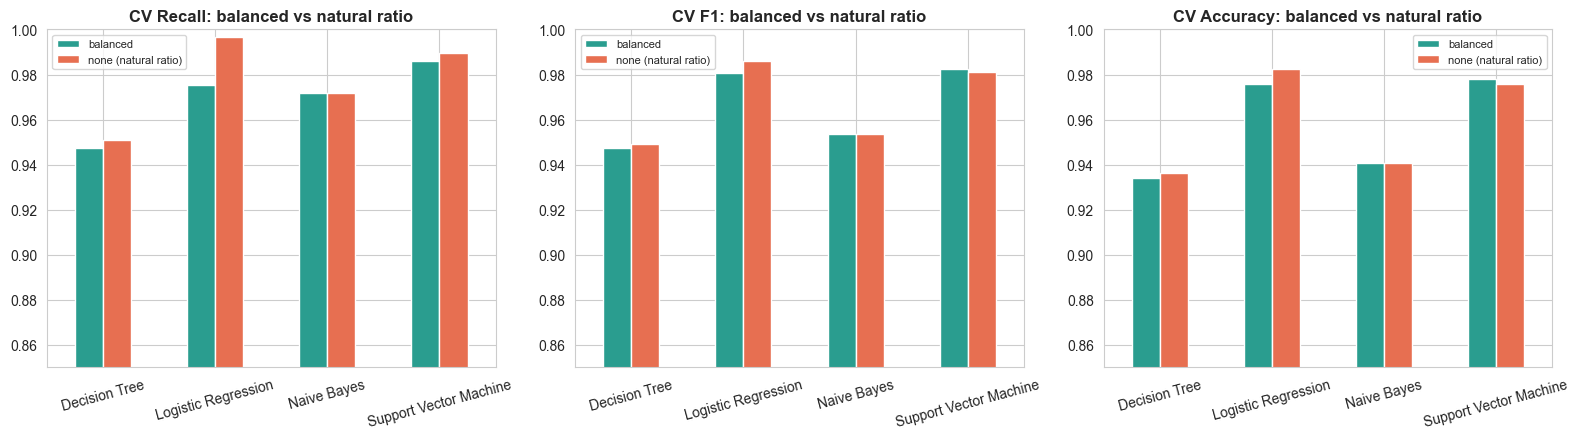

In [16]:
rows = []
for name, cvr in cv_tables.items():
    col = next((c for c in cvr.columns
                if c in ('param_model__class_weight', 'param_model__priors')), None)
    if col is None:
        continue   # KNN has no class-weighting option
    mode = cvr[col].apply(lambda v: 'balanced' if isinstance(v, (str, list)) else 'none (natural ratio)')
    for m, sub in cvr.groupby(mode):
        best = sub.loc[sub['mean_test_f1'].idxmax()]
        rows.append({'Model': name, 'Weighting': m,
                     **{k: best[f'mean_test_{s}'] for k, s in
                        [('CV Accuracy', 'accuracy'), ('CV AUC', 'auc'), ('CV Precision', 'precision'),
                         ('CV Recall', 'recall'), ('CV F1', 'f1'), ('CV MCC', 'mcc')]}})

balance_df = pd.DataFrame(rows).set_index(['Model', 'Weighting']).round(4)
display(balance_df)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, metric in zip(axes, ['CV Recall', 'CV F1', 'CV Accuracy']):
    balance_df[metric].unstack().plot(kind='bar', ax=ax, color=['#2a9d8f', '#e76f51'], rot=15)
    ax.set_title(f'{metric}: balanced vs natural ratio', fontweight='bold')
    ax.set_xlabel(''); ax.set_ylim(0.85, 1.0); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

> **NOTE:** The dataset itself was **not balanced**. The rows stay at the natural ~63/37 ratio. Any *training* balancing happens only through class weights, chosen per model by cross-validation.

**Imbalance verdict:**
- At a 1.7:1 ratio the effect of weighting is small. For **Logistic Regression** and **Decision Tree**, CV preferred the natural ratio (CV F1 0.986 vs 0.981 and 0.949 vs 0.947): balancing traded a little recall for precision and did not pay off.
- For the **SVM**, balanced weights gave a marginally better CV F1 (0.9825 vs 0.9810) and MCC, so `class_weight='balanced'` was kept.
- For **Naive Bayes**, 50/50 priors gave *identical* CV scores to the natural priors (the likelihood dominates with 30 features), so the natural priors were kept.
- **AUC barely moves** with weighting - it shifts the decision threshold rather than improving how well cases are ranked.
- **Conclusion:** leave the data itself unbalanced (no resampling, test set at the true ratio) and let class weighting be chosen per model by cross-validation. The imbalance is mild enough that it is not the main driver of model differences.

## Section 6: Evaluation and Comparison (held-out test set)

In [17]:
metric_cols = ['Accuracy', 'AUC', 'Precision', 'Recall', 'F1', 'MCC']
results_df = pd.DataFrame(results).T
results_df[metric_cols + ['CV F1']] = results_df[metric_cols + ['CV F1']].astype(float).round(4)
display(results_df)

,Accuracy,AUC,Precision,Recall,F1,MCC,CV F1,Tuning Time (s),Refit Time (s)
Logistic Regression,0.9737,0.9957,0.9726,0.9861,0.9793,0.9433,0.9861,3.6,0.011
Decision Tree,0.8772,0.9593,0.9531,0.8472,0.8971,0.7542,0.9493,1.3,0.007
KNN,0.9649,0.9714,0.9595,0.9861,0.9726,0.9245,0.9774,0.4,0.003
Naive Bayes,0.9474,0.9878,0.9459,0.9722,0.9589,0.8864,0.9535,0.3,0.003
Support Vector Machine,0.9737,0.9967,0.9859,0.9722,0.9790,0.9439,0.9825,0.4,0.010


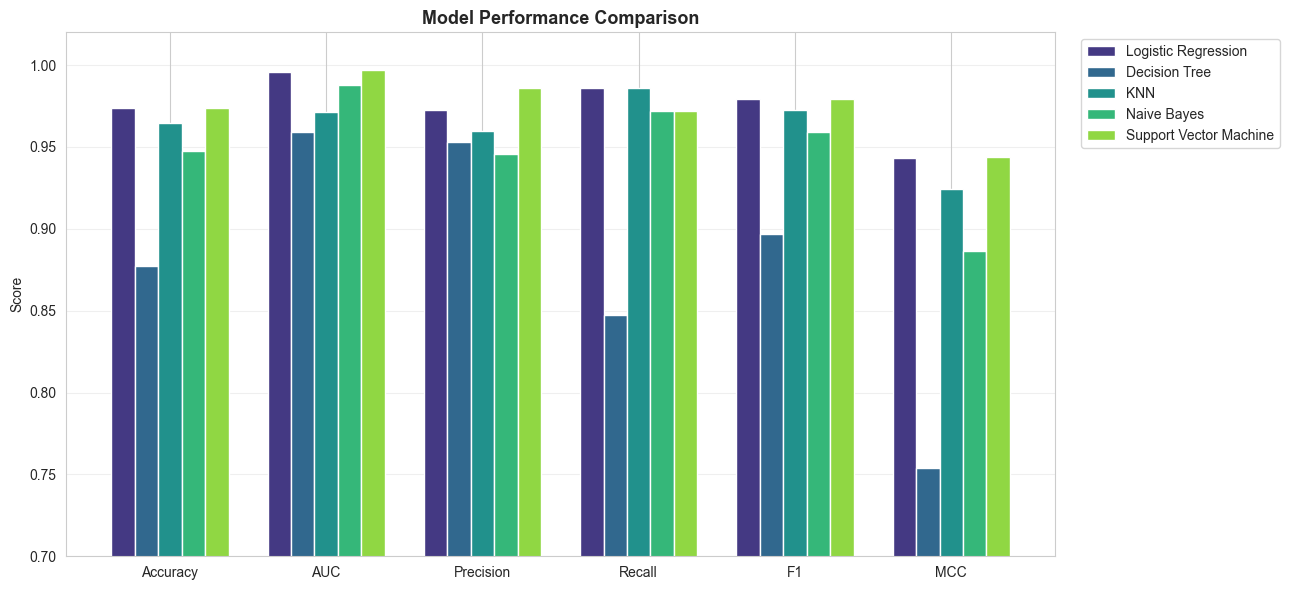

In [18]:
plot_df = results_df[metric_cols]

fig, ax = plt.subplots(figsize=(13, 6))
x = np.arange(len(metric_cols))
width = 0.15
palette = sns.color_palette('viridis', len(plot_df))

for i, (name, row) in enumerate(plot_df.iterrows()):
    ax.bar(x + i * width, row.values, width, label=name, color=palette[i])

ax.set_xticks(x + width * (len(plot_df) - 1) / 2)
ax.set_xticklabels(metric_cols)
ax.set_ylabel('Score')
ax.set_ylim(0.7, 1.02)
ax.set_title('Model Performance Comparison', fontsize=13, fontweight='bold')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

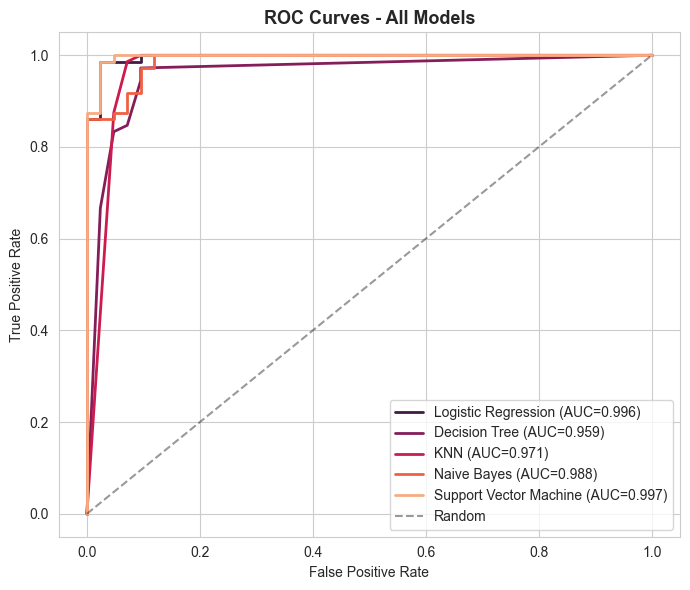

In [19]:
plt.figure(figsize=(7, 6))
palette = sns.color_palette('rocket', len(roc_data))
for i, (name, (fpr, tpr, auc)) in enumerate(roc_data.items()):
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})', color=palette[i], linewidth=2)
plt.plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - All Models', fontsize=13, fontweight='bold')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

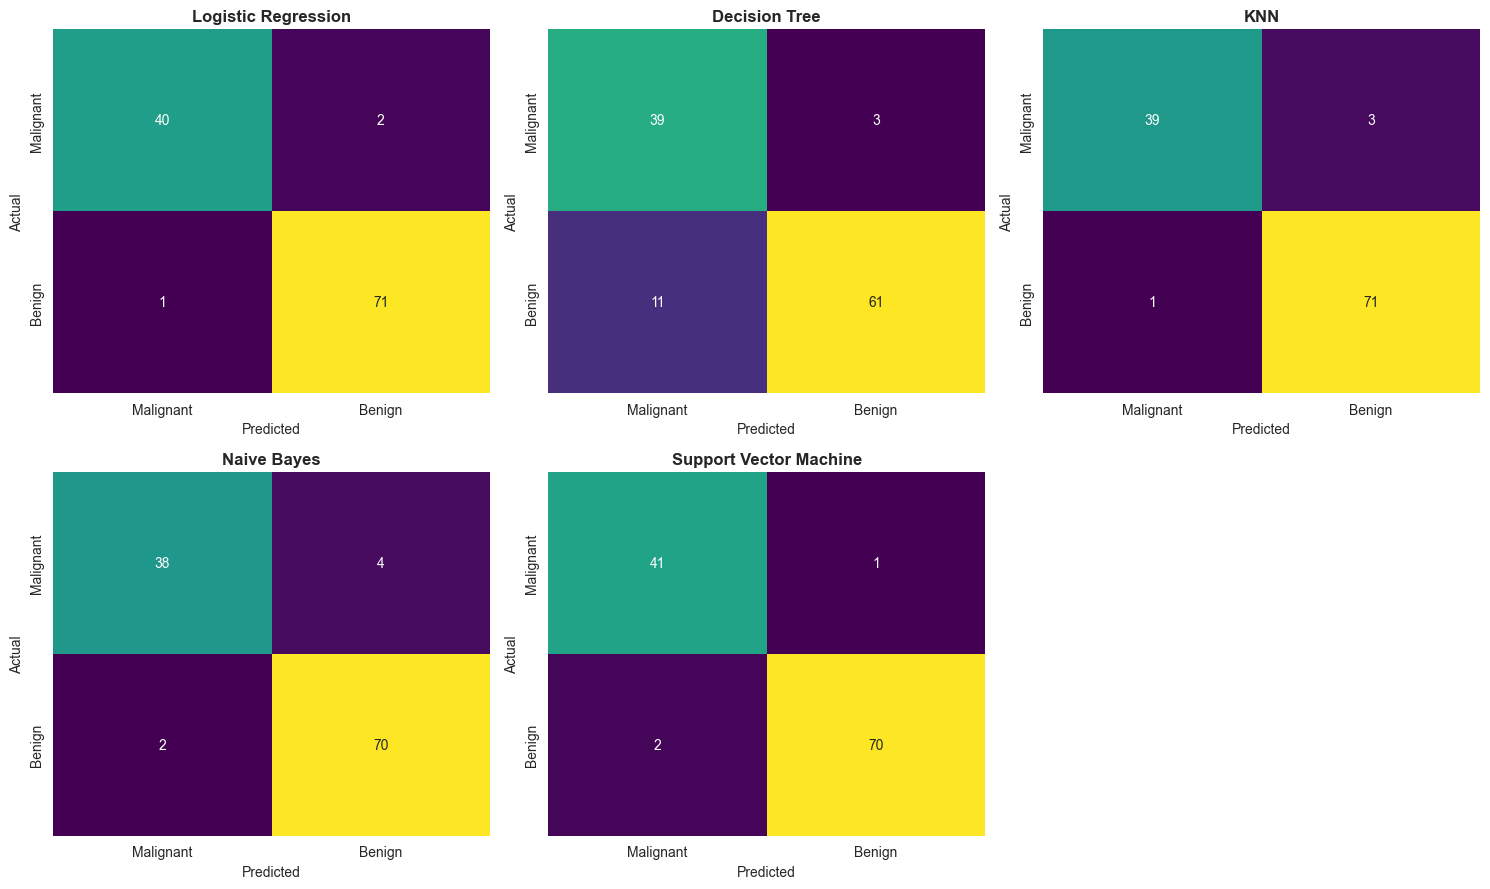

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, (name, pipe) in enumerate(fitted_pipelines.items()):
    cm = confusion_matrix(y_test, pipe.predict(X_test))
    sns.heatmap(cm, annot=True, fmt='d', cmap='viridis', ax=axes[i], cbar=False,
                xticklabels=['Malignant', 'Benign'], yticklabels=['Malignant', 'Benign'])
    axes[i].set_title(name, fontweight='bold')
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')

axes[-1].axis('off')
plt.tight_layout()
plt.show()

## Section 7: Save Models and Artifacts

In [21]:
os.makedirs('model', exist_ok=True)

name_to_file = {
    'Logistic Regression': 'logistic_regression',
    'Decision Tree': 'decision_tree',
    'KNN': 'knn',
    'Naive Bayes': 'naive_bayes',
    'Support Vector Machine': 'svm',
}

for name, pipe in fitted_pipelines.items():
    fname = f"model/{name_to_file[name]}.joblib"
    joblib.dump(pipe, fname, compress=3)
    print(f"Saved {fname}  ({os.path.getsize(fname) / 1024:.0f} KB)")

results_df.to_csv('model/comparison_table.csv')
best_params_df.to_csv('model/best_hyperparameters.csv')
balance_df.to_csv('model/class_balance_cv.csv')
print("\nSaved model/comparison_table.csv, model/best_hyperparameters.csv, model/class_balance_cv.csv")

# Sanity check: reload a saved pipeline and score test_data.csv exactly as the app does
reloaded = joblib.load('model/logistic_regression.joblib')
td = pd.read_csv('test_data.csv')
print("Reload check — LR test F1:",
      round(f1_score(td['target'], reloaded.predict(td.drop(columns='target'))), 4))

Saved model/logistic_regression.joblib  (2 KB)
Saved model/decision_tree.joblib  (3 KB)
Saved model/knn.joblib  (102 KB)
Saved model/naive_bayes.joblib  (3 KB)
Saved model/svm.joblib  (15 KB)

Saved model/comparison_table.csv, model/best_hyperparameters.csv, model/class_balance_cv.csv
Reload check — LR test F1: 0.9793


## Section 8: Observations

Metrics treat **Benign (1)** as the positive class. The test set has only 114 rows, so one
patient is about 0.9 accuracy points; differences of a few thousandths between models are within noise.

| Model | Tuned hyperparameters | Observation |
|---|---|---|
| **Logistic Regression** | `C=0.1`, `class_weight=None` | Best F1 (0.979) and recall (0.986, tied with KNN), accuracy 0.974, MCC 0.943, AUC 0.996. The tuned `C=0.1` means fairly strong regularisation, which suits the heavily collinear features (radius/perimeter/area): the penalty spreads weight across the correlated columns instead of overfitting any one of them. The classes are close to linearly separable once scaled, so a linear boundary is enough. It is also the easiest to explain via its coefficients. |
| **Decision Tree** | `criterion='entropy'`, `max_depth=4`, `min_samples_leaf=5`, `class_weight=None` | Clearly the weakest model: accuracy 0.877, recall 0.847, F1 0.897, MCC 0.754. Axis-aligned splits approximate the smooth, oblique boundary between correlated size features poorly, and a single tree has high variance on 455 training rows. CV kept it shallow (depth 4) to limit overfitting. Its strength is interpretability: the rules can be read directly. |
| **KNN** | `n_neighbors=3`, `weights='uniform'`, `p=1` | Strong: accuracy 0.965, recall 0.986 (tied best), F1 0.973. Manhattan distance (`p=1`) won over Euclidean, which is less dominated by a few large coordinate differences in 30 dimensions. Scaling inside the pipeline is essential here. Its AUC (0.971) is lower than the others because a 3-neighbour vote gives coarse probabilities (only 4 distinct values), which limits ranking quality. |
| **Naive Bayes** | `var_smoothing=0.1`, `priors=None` | Accuracy 0.947, F1 0.959, MCC 0.886, but AUC 0.988 is much better than its accuracy suggests: it ranks cases well while its probabilities are poorly calibrated. The independence assumption is clearly violated by the near-duplicate size features, which costs it threshold-based accuracy. Smoothing (`0.1`) was preferred over the default `1e-9`. |
| **Support Vector Machine** | `C=10`, `gamma=0.01`, `class_weight='balanced'` | Best AUC (0.997), best precision (0.986) and best MCC (0.944); F1 0.979 is just 0.0003 below Logistic Regression and accuracy is identical (0.974). The RBF kernel with a small `gamma` is a smooth, near-linear boundary. Balanced weights gave a slight CV gain. On this small dataset it tunes in well under a second. |
| **Overall winner** | **Logistic Regression** | It ranks first by the F1-then-MCC rule, ties for the highest recall (0.986, so it misses the fewest Benign cases) and is within 0.001 of the best AUC. SVM is a virtual tie (same accuracy; it is ahead on AUC, precision and MCC), so the choice between them is not statistically meaningful on 114 test rows; LR is preferred for simplicity and interpretability. |

### Overall Ranking

| Rank | Model | F1 | MCC | AUC | Accuracy | In short |
|---|---|---|---|---|---|---|
| 1 | **Logistic Regression** | **0.979** | 0.943 | 0.996 | 0.974 | Best F1, top recall, simplest and most explainable |
| 2 | Support Vector Machine | 0.979 | **0.944** | **0.997** | 0.974 | Virtual tie: best AUC, precision and MCC |
| 3 | KNN | 0.973 | 0.925 | 0.971 | 0.965 | Top recall, but coarse probabilities limit AUC |
| 4 | Naive Bayes | 0.959 | 0.886 | 0.988 | 0.947 | Ranks well, but independence assumption costs accuracy |
| 5 | Decision Tree | 0.897 | 0.754 | 0.959 | 0.877 | Interpretable, but clearly the weakest |

*Ranked by F1, with MCC as tie-breaker.*

> **Winner: Logistic Regression** (SVM is a near-tied co-winner). It leads on F1, ties for the best recall, is within 0.001 AUC of SVM, and is the simplest to explain.